# P1-04. 사전학습 모델 전이학습 + 뇌 영역 자르기 + 데이터 증강

**이 노트북의 목표**: 실무에서 실제로 쓰는 방식인 **사전학습(pretrained) 모델**을 가져와서 우리 데이터에 맞게 다시 학습(fine-tuning)하고,  
노트북 3 Grad-CAM에서 발견한 **지름길(notumor·pituitary가 머리 테두리를 보고 맞힘)**을 줄여볼 수 있는지 확인해요.

**이 노트북에서 확인할 질문 4가지** (실행 전에 예측해보세요!)
1. **사전학습의 효과**: 같은 ResNet50 구조인데, ImageNet으로 미리 학습된 가중치로 시작하면 처음부터 학습하는 것보다 얼마나 좋을까?
2. **뇌 영역 자르기 + 증강의 효과**: 성능이 오를까? 그리고 Grad-CAM이 **테두리 대신 뇌 안쪽을 보게** 바뀔까?
3. **모델 구조 비교**: ResNet50 vs EfficientNet-B0 vs ViT(Transformer) — 어느 게 이 데이터에 잘 맞을까?
4. **누수**: train을 거의 외우는 강한 모델에서는 누수 효과가 다시 커질까?

**노트북 3에서 달라진 점**

| 항목 | 노트북 3 | 노트북 4 | 🎯 왜 바꿨나 |
|---|---|---|---|
| 모델 | 직접 만든 CNN | **timm 사전학습 모델** (ResNet50, EfficientNet-B0, ViT-Small) | 실무 표준. 적은 데이터로도 높은 성능 |
| 입력 | 흑백 1채널, 128×128 | **3채널, 224×224** | 사전학습 모델이 ImageNet(컬러, 224)으로 학습돼서 그 형식에 맞춤 (노트북 1에서 정한 방침) |
| 정규화 | train 픽셀 평균·표준편차 | **ImageNet 평균·표준편차** | 사전학습 때와 같은 기준으로 입력을 맞춰야 가중치가 제대로 작동 |
| 전처리 | 그냥 리사이즈 | **뇌 영역 기준 자르기** (선택) | 클래스마다 다른 여백·확대 정도(지름길)를 없애려고 |
| 증강 | 없음 | **뒤집기·회전·확대·밝기 대비** (선택) | 외우기 감소 + 특정 구도·밝기에 덜 의존하게 |
| 옵티마이저 | Adam lr 3e-4 + cosine | **AdamW** + cosine, 사전학습 모델은 **lr 1e-4** | 이미 좋은 가중치를 *살짝만* 고치려고 보폭을 줄임. AdamW는 가중치가 너무 커지는 걸 막아줌 |
| 속도 | 일반 계산 | **혼합 정밀도(AMP)** | GPU에서 계산을 일부 16비트로 해서 약 2배 빠르게 |

> 💡 **실행 시간**: 실험 5개를 다 돌리면 3080 한 장에서 **30분~1시간** 정도 걸려요. 3번 셀의 `GPU_ID`와 `RUN_TAGS`로 GPU 두 장에 나눠 돌리는 방법을 안내해뒀어요.  
> 실행 후 **2-2(자르기 예시), 5(비교표), 6(누수), 7(Grad-CAM)** 출력을 Claude에게 보내주세요.

## 0. 준비

In [1]:
import random, time, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image
from tqdm.auto import tqdm
from scipy import ndimage

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, classification_report, confusion_matrix,
                             roc_auc_score, balanced_accuracy_score)

_avail = {f.name for f in font_manager.fontManager.ttflist}
for _f in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if _f in _avail:
        plt.rcParams["font.family"] = _f; break
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all()
print("timm 버전:", timm.__version__)

d:\yerimlee\medimg-study\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


timm 버전: 1.0.31


## 1. 데이터 목록 (노트북 2·3과 동일한 분할)

> 🎯 **왜 같은 분할?** MLP(노트북 2), 직접 만든 CNN(노트북 3)과 **같은 이미지로 학습·평가해야** 공정하게 비교할 수 있어요.

In [2]:
DATA_ROOT = Path("../../data/raw").resolve()
OUT = Path("../../outputs/p1").resolve()
RES_DIR = OUT / "nb4_results"; RES_DIR.mkdir(parents=True, exist_ok=True)

clean = pd.read_csv(OUT / "brain_index_clean.csv")
full  = pd.read_csv(OUT / "brain_index.csv")
for d in (clean, full):
    d["abs_path"] = d["path"].map(lambda p: str(DATA_ROOT / p))

CLASSES = sorted(clean["label"].unique())
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
train_all = clean[clean["split"] == "train"]
test_df   = clean[clean["split"] == "test"].reset_index(drop=True)
train_df, val_df = train_test_split(train_all, test_size=0.15, stratify=train_all["label"], random_state=SEED)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)
print(f"train {len(train_df):,} / val {len(val_df):,} / test {len(test_df):,}  (4,333 / 765 / 882 이어야 해요)")

train 4,333 / val 765 / test 882  (4,333 / 765 / 882 이어야 해요)


## 2. 뇌 영역 기준 자르기 (foreground crop)

> 🎯 **왜 하나요?**  
> 노트북 1에서 *"pituitary는 머리가 화면을 꽉 채운 확대 구도"*, 노트북 3 Grad-CAM에서 *"notumor·pituitary는 머리 테두리를 보고 판단"*하는 걸 봤어요.  
> 사진마다 **여백과 확대 정도가 다르면** 모델이 그걸 단서로 쓸 수 있어요.  
> 그래서 모든 사진에서 **뇌(머리)가 있는 영역만 찾아서 잘라내고**, 같은 크기로 맞춰서 *"뇌가 화면을 똑같이 채우게"* 만들어요.

**방법** (딥러닝 아님, 간단한 영상처리)
1. 밝기가 일정 이상인 픽셀만 남김 → 까만 배경 제거
2. 작은 점·글자 같은 잡티를 지움 (opening)
3. **가장 큰 덩어리** = 머리 → 그 덩어리를 감싸는 네모 찾기 (글자는 머리와 떨어져 있어서 대부분 빠짐)
4. 네모를 정사각형으로 맞추고 약간의 여백을 둔 뒤 자르기 → 256×256으로 리사이즈

In [3]:
CACHE_SIZE = 256   # 메모리에 저장할 크기 (학습 때 224로 자르거나 줄임)

def brain_crop(a, thr=20, margin=0.04):
    """a: 흑백 uint8 배열 → 머리 영역만 정사각형으로 잘라서 반환"""
    m = a > thr
    m = ndimage.binary_opening(m, iterations=2)
    lab, n = ndimage.label(m)
    if n == 0:
        return a
    sizes = ndimage.sum(m, lab, range(1, n + 1))
    ys, xs = np.where(lab == (np.argmax(sizes) + 1))
    y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()
    side = max(y1 - y0, x1 - x0) * (1 + 2 * margin)          # 정사각형 + 여백 → 비율 유지(찌그러짐 방지)
    cy, cx = (y0 + y1) / 2, (x0 + x1) / 2
    y0, y1 = int(max(cy - side / 2, 0)), int(min(cy + side / 2, a.shape[0]))
    x0, x1 = int(max(cx - side / 2, 0)), int(min(cx + side / 2, a.shape[1]))
    return a[y0:y1, x0:x1]

def load_pair(path):
    with Image.open(path) as im:
        a = np.asarray(im.convert("L"))
    raw  = np.asarray(Image.fromarray(a).resize((CACHE_SIZE, CACHE_SIZE), Image.BILINEAR))
    crop = np.asarray(Image.fromarray(brain_crop(a)).resize((CACHE_SIZE, CACHE_SIZE), Image.BILINEAR))
    return raw, crop

def build_cache(df, desc):
    raws, crops = zip(*[load_pair(p) for p in tqdm(df["abs_path"], desc=desc)])
    labels = torch.tensor(df["label"].map(CLS2IDX).values, dtype=torch.long)
    return {"raw": torch.from_numpy(np.stack(raws)).unsqueeze(1),      # N×1×256×256 (uint8)
            "crop": torch.from_numpy(np.stack(crops)).unsqueeze(1), "y": labels}

cache = {name: build_cache(d, name) for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
mb = sum(c[k].numel() for c in cache.values() for k in ("raw", "crop")) / 1024**2
print(f"메모리 사용: 약 {mb:.0f}MB (uint8로 저장해서 작게 유지)")

test: 100%|██████████| 882/882 [00:17<00:00, 49.95it/s] 


메모리 사용: 약 748MB (uint8로 저장해서 작게 유지)


### 2-1. 자르기 전/후 비교

> 🎯 **확인할 것**: 클래스마다 달랐던 여백·확대 정도가 **비슷해졌는지**, 그리고 머리가 잘려나가지 않았는지 (특히 가장자리에 붙은 meningioma!)

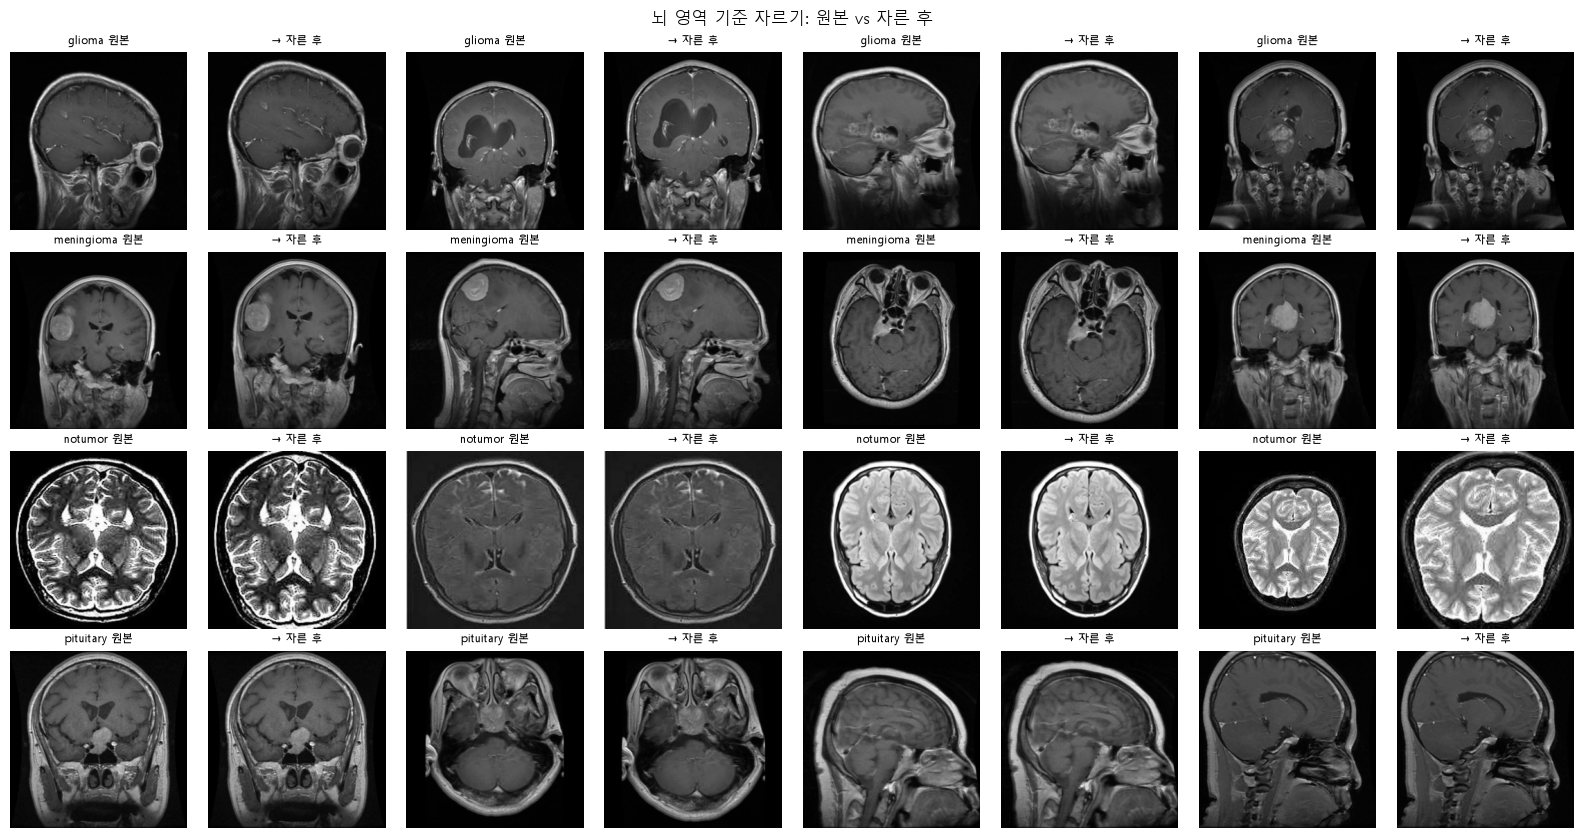

In [4]:
fig, axes = plt.subplots(4, 8, figsize=(16, 8.5))
rng = np.random.default_rng(1)
for r, cls in enumerate(CLASSES):
    idx = rng.choice(np.where(cache["test"]["y"].numpy() == CLS2IDX[cls])[0], 4, replace=False)
    for k, i in enumerate(idx):
        axes[r, k * 2].imshow(cache["test"]["raw"][i, 0], cmap="gray");  axes[r, k * 2].set_title(f"{cls} 원본", fontsize=8)
        axes[r, k * 2 + 1].imshow(cache["test"]["crop"][i, 0], cmap="gray"); axes[r, k * 2 + 1].set_title("→ 자른 후", fontsize=8)
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("뇌 영역 기준 자르기: 원본 vs 자른 후"); plt.tight_layout(); plt.show()

## 3. 증강(augmentation)과 Dataset

> 🎯 **증강이 뭐고 왜 하나요?**  
> 학습할 때마다 사진을 **조금씩 랜덤하게 변형**해서 넣어요. 같은 사진도 epoch마다 조금씩 다르게 보이니까  
> (1) 모델이 사진을 **통째로 외우기 어려워지고** (노트북 3의 과적합·val 불안정 완화),  
> (2) **특정 구도·위치·밝기에 덜 의존**하게 돼요 (지름길 완화).  
> ⚠️ 증강은 **train에만** 해요. val·test는 실제 성적을 재는 거라 원본 그대로 평가해요.

| 증강 | 내용 | 의료영상에서 주의할 점 |
|---|---|---|
| RandomResizedCrop | 85~100% 범위를 랜덤하게 잘라 224로 | 너무 많이 자르면 종양이 잘림 → 85%까지만 |
| HorizontalFlip | 좌우 반전 | 뇌는 좌우가 거의 대칭이라 OK. **상하 반전은 안 함** (해부학적으로 말이 안 됨) |
| Rotation | ±10도 회전 | 촬영 시 머리 기울기 정도만 |
| ColorJitter | 밝기·대비 ±20% | 장비·촬영 조건 차이를 흉내 → 밝기 지름길 완화 |

**3채널 + ImageNet 정규화**: 흑백 1채널을 3번 복사하고, ImageNet의 평균·표준편차로 정규화해요 (노트북 1에서 정한 방침).

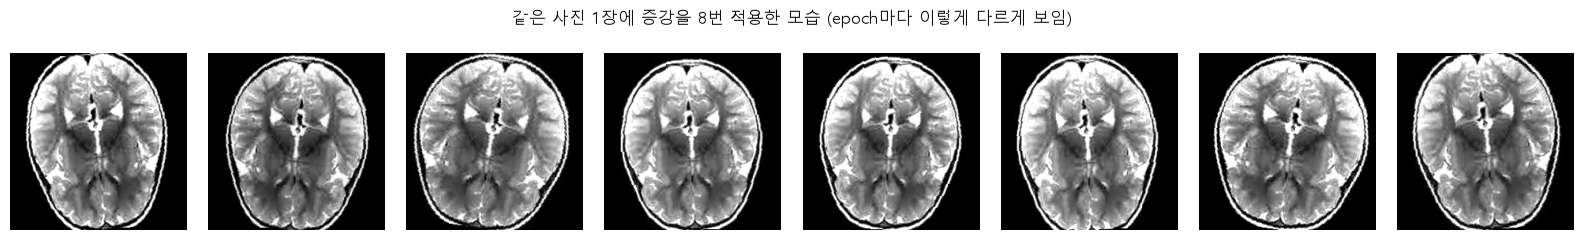

In [5]:
IMG = 224
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

train_aug = v2.Compose([
    v2.RandomResizedCrop(IMG, scale=(0.85, 1.0), ratio=(0.9, 1.1), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.RandomRotation(10),
    v2.ColorJitter(brightness=0.2, contrast=0.2),
])
eval_tf = v2.Resize((IMG, IMG), antialias=True)

class CachedDS(Dataset):
    def __init__(self, imgs, labels, tf):
        self.imgs, self.labels, self.tf = imgs, labels, tf
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        x = self.tf(self.imgs[i])                         # uint8 1×256×256 → 변형 → 1×224×224
        x = x.float().div(255).repeat(3, 1, 1)            # 0~1, 흑백을 3채널로 복사
        return (x - IMAGENET_MEAN) / IMAGENET_STD, self.labels[i]

def make_loaders(crop, aug, bs=32):
    key = "crop" if crop else "raw"
    tr = CachedDS(cache["train"][key], cache["train"]["y"], train_aug if aug else eval_tf)
    va = CachedDS(cache["val"][key],   cache["val"]["y"],   eval_tf)
    te = CachedDS(cache["test"][key],  cache["test"]["y"],  eval_tf)
    return (DataLoader(tr, batch_size=bs, shuffle=True), DataLoader(va, batch_size=128), DataLoader(te, batch_size=128))

# 증강이 어떻게 보이는지: 같은 사진 1장을 8번 변형
x0 = cache["train"]["crop"][0]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax in axes:
    ax.imshow(train_aug(x0)[0], cmap="gray"); ax.axis("off")
plt.suptitle("같은 사진 1장에 증강을 8번 적용한 모습 (epoch마다 이렇게 다르게 보임)"); plt.tight_layout(); plt.show()

## 4. 실험 설계

> 🎯 **왜 이렇게 5개를 비교하나요?** 한 번에 **한 가지만 바꿔서** 비교해야 무엇 때문에 성능이 변했는지 알 수 있어요 (정형 데이터의 통제 실험과 같은 원리).

| 실험 | 모델 | 사전학습 | 자르기 | 증강 | 비교해서 알 수 있는 것 |
|---|---|---|---|---|---|
| **E1** | ResNet50 | ✅ | ❌ | ❌ | 노트북 3 CNN과 비교 → **사전학습 모델의 기본 실력** |
| **E2** | ResNet50 | ✅ | ✅ | ✅ | **E1 vs E2** → 자르기+증강의 효과 (성능 & Grad-CAM) |
| **E3** | ResNet50 | ❌ | ✅ | ✅ | **E2 vs E3** → 같은 구조에서 **사전학습의 효과** |
| **E4** | EfficientNet-B0 | ✅ | ✅ | ✅ | **E2 vs E4** → 가볍고 효율적인 CNN과 비교 |
| **E5** | ViT-Small | ✅ | ✅ | ✅ | **E2 vs E5** → CNN이 아닌 **Transformer** 구조와 비교 |

**모델 소개** (모두 `timm`이 **허깅페이스 Hub**에서 사전학습 가중치를 받아와요)
- **ResNet50**: 2015년 등장. 층을 50개 쌓으면서 "지름길 연결(skip connection)"로 깊어도 학습이 잘 되게 만든 CNN의 표준
- CNN은 층이 깊어질수록 기울기를 전달할때 앞쪽층까지 신호가 잘 가지 않는 문제 (backward)가 있었는데, 기울기를 전달할때 미분해서 곱하게 되는데, 미분값이 1보다 조금만 작아져도 많이 곱하면 0에 가까워지는 문제가 있음 --> 뒤쪽은 학습이 잘 되는데 앞쪽은 학습이 안되는 문제가 있음 (Vanishing gradient 문제)
- CNN의 이런 한계를 고치기 위해서 Residual 을 추가함. +1과 같이 특정값을 더하는 과정을 붙이게 됨 --> 20층 뿐만 아니라 50층, 100층까지도 잘 전달이 됨 
- **EfficientNet-B0**: 적은 파라미터로 높은 성능을 내도록 설계된 CNN (ResNet50의 약 1/5 크기)
- **ViT-Small**: 이미지를 16×16 조각으로 나눠 **문장의 단어처럼** 다루는 Transformer. ChatGPT 같은 언어모델과 같은 계열

> 💡 **GPU 두 장 쓰기**: 이 노트북을 복사해서(`04_pretrained_gpu1.ipynb`) 한쪽은 `GPU_ID=0, RUN_TAGS=["E1","E2","E3"]`,  
> 다른 쪽은 `GPU_ID=1, RUN_TAGS=["E4","E5"]`로 동시에 돌리면 시간이 반으로 줄어요. 결과는 파일로 저장돼서 5번 셀이 둘 다 모아서 비교해줘요.

## 📚 메모: 모델 구조 정리 — SimpleCNN, ResNet50, EfficientNet-B0, ViT-Small

### 0. 먼저 알아둘 공통 개념

**shape 읽기**: `채널 × 높이 × 너비` (배치까지 붙으면 `N × C × H × W`)
- **채널** = 겹쳐 쌓인 지도(이미지)의 장수. 입력에선 색(흑백 1, RGB 3), Conv를 지난 뒤엔 **필터가 찾은 패턴 지도**의 장수
- **크기(H×W)** = 지도 한 장의 해상도

**채널과 크기는 서로 독립적으로 결정됨**

| 무엇 | 누가 결정하나 |
|---|---|
| 채널 수 | Conv의 **필터 개수** (`Conv2d(32, 64)` → 64채널) |
| 크기 | **풀링**이 있거나 Conv의 **stride가 2**일 때만 줄어듦 |

**크기를 줄이는 두 가지 방법**

| 경우 | 크기 | 쓰는 모델 |
|---|---|---|
| Conv **stride 1** + 패딩 1 | 그대로 | 모든 모델의 기본 Conv |
| Conv stride 1 + **MaxPool(2)** | 반으로 | **우리 SimpleCNN** (매 블록) |
| Conv **stride 2** | 반으로 | **ResNet, EfficientNet** (줄이고 싶은 지점에서만) |

- **stride** = 필터가 한 번에 이동하는 칸 수. stride 2는 두 칸씩 건너뛰어서 출력 칸이 절반만 생김 (128칸을 두 칸씩 밟으면 64번)
- **padding** = 가장자리에 0을 두르는 것. 3×3 필터면 `padding=1`이면 크기 유지 (공식: 패딩 = (필터 크기 − 1) ÷ 2)
  - 출력 크기 = 입력 + 2×패딩 − 필터 크기 + 1 → 128 + 2 − 3 + 1 = 128
- **매번 줄이지 않는 이유**: 너무 빨리 줄이면 위치 정보가 금방 사라짐 → 같은 크기에서 블록을 여러 번 반복해 충분히 패턴을 뽑고 나서 줄임

**모든 CNN의 공통 뼈대**: 크기는 점점 줄고 채널은 점점 늘다가 → 마지막에 **Global Average Pool**(지도 한 장 = 평균값 1개) → **Linear(채널 수 → 4)**

---

### 1. SimpleCNN (노트북 3, 직접 만든 것) — 0.4M 파라미터

블록 = `Conv 3×3 (stride 1, padding 1) → BatchNorm → ReLU → MaxPool(2)`
→ Conv가 채널을 바꾸고, **MaxPool이 크기를 반으로** (역할 분담)

| 단계 | 출력 shape | 크기를 줄인 것 |
|---|---|---|
| 입력 | 1 × 128 × 128 | – |
| block1 | 32 × 64 × 64 | MaxPool |
| block2 | 64 × 32 × 32 | MaxPool |
| block3 | 128 × 16 × 16 | MaxPool |
| block4 | 256 × 8 × 8 | MaxPool |
| Global Avg Pool → Linear | 256 → **4** | – |

- 모든 블록에 MaxPool을 넣어서 **"채널이 늘면 크기는 반"이 항상 같이 움직임** → 단순하게 만들려고 그렇게 설계한 것일 뿐, 규칙은 아님

---

### 2. ResNet50 — 23.5M 파라미터, "깊게 쌓아도 학습되는 CNN"

**배경 문제: 기울기 소실 (vanishing gradient)**
- `backward()`는 손실(맨 끝)에서 출발해 층을 거꾸로 올라가며 기울기를 계산
- 연쇄법칙 때문에 **층마다 미분값이 곱해짐** → 각 층 미분이 0.5면 20층 뒤엔 0.5²⁰ ≈ 0.000001
- 결과: 뒤쪽 층만 학습되고 **앞쪽 층(기초 패턴 담당)은 거의 안 바뀜** → 2015년 전엔 20층 넘게 쌓으면 오히려 성능 하락
- 비유: 말 전달 게임에서 맨 앞사람까지 목소리가 안 들림

**해결: 지름길 연결 (skip connection, residual)**
- 일반 블록: 출력 = F(x) / ResNet 블록: 출력 = **F(x) + x** (입력을 출력에 그대로 더함)
- 미분하면 F'(x) **+ 1** → 기울기가 최소한 그대로 통과하는 길이 생김 (맨 앞까지 직통 전화)
- 블록은 "입력에 무엇을 더할지(차이)"만 배우면 됨 → 50층, 100층도 학습 가능
- ⚠️ 여기서 "지름길"은 좋은 의미. 데이터 지름길(shortcut learning)과는 다른 말

**구조** (입력 224×224) — SimpleCNN과 같은 뼈대

| 단계 | 출력 shape | 크기를 줄인 것 |
|---|---|---|
| 시작 (7×7 Conv stride 2 + MaxPool) | 64 × 56 × 56 | stride 2 + MaxPool |
| 단계 1 (블록 3개) | 256 × 56 × 56 | **없음 (stride 1) → 채널만 늘어남** |
| 단계 2 (블록 4개) | 512 × 28 × 28 | 첫 블록 Conv stride 2 |
| 단계 3 (블록 6개) | 1024 × 14 × 14 | 첫 블록 Conv stride 2 |
| 단계 4 (블록 3개) | 2048 × 7 × 7 | 첫 블록 Conv stride 2 |
| Global Avg Pool → Linear | 2048 → **4** | – |

- 시작 부분에만 MaxPool이 있고, 그 뒤로는 **줄이고 싶은 지점의 Conv만 stride 2**, 나머지는 stride 1
- 우리가 `num_classes=4`로 만들면 마지막 Linear(2048 → 1000)만 **Linear(2048 → 4)로 교체**되고 나머지는 사전학습 가중치 그대로

---

### 3. EfficientNet-B0 — 4.0M 파라미터 (ResNet50의 약 1/6), "같은 성능을 가볍게"

**구조** (입력 224×224) — 역시 같은 뼈대, 채널 수가 훨씬 적고 단계가 7개

| 단계 | 출력 shape | 크기를 줄인 것 |
|---|---|---|
| 시작 (3×3 Conv stride 2) | 32 × 112 × 112 | stride 2 |
| 단계 1 (블록 1개) | 16 × 112 × 112 | **없음 → 크기 그대로 (채널은 오히려 줄어듦)** |
| 단계 2 (블록 2개) | 24 × 56 × 56 | stride 2 |
| 단계 3 (블록 2개) | 40 × 28 × 28 | stride 2 |
| 단계 4 (블록 3개) | 80 × 14 × 14 | stride 2 |
| 단계 5 (블록 3개) | 112 × 14 × 14 | **없음 → 채널만 늘어남** |
| 단계 6 (블록 4개) | 192 × 7 × 7 | stride 2 |
| 단계 7 (블록 1개) | 320 × 7 × 7 | 없음 |
| 1×1 Conv → Global Avg Pool → Linear | 1280 → **4** | – |

- 224 → 112 → 56 → 28 → 14 → 7로 **딱 5번만** 줄이도록 설계됨

**블록 안 (MBConv) — SimpleCNN 블록과 비교**

| 순서 | SimpleCNN 블록 | EfficientNet 블록 |
|---|---|---|
| 1 | Conv 3×3 (모든 채널 한꺼번에) | 1×1 Conv: 채널 수 늘리기 |
| 2 | BatchNorm → ReLU | **3×3 Conv, 채널마다 따로** (depthwise) |
| 3 | MaxPool | **채널별 중요도 곱하기** (Squeeze-and-Excitation) |
| 4 | – | 1×1 Conv: 채널 섞어서 줄이기 + 지름길 연결 (ResNet처럼) |

**핵심 ① 계산 쪼개기 (depthwise separable convolution)** — 노트북 3 block2(32 → 64채널)로 비교
- 일반 Conv: 필터 64개가 각각 32채널 전부를 3×3으로 → 64 × 32 × 9 = **18,432개**
- EfficientNet: ① 32채널 각각에 3×3 하나씩 (모양 보기) 32 × 9 = 288 + ② 1×1 필터 64개로 채널 섞기 (조합) 64 × 32 = 2,048 → **2,336개 (약 1/8)**
- "모양 보는 일"과 "채널 섞는 일"을 나눠서 가벼워짐

**핵심 ② 채널마다 볼륨 조절 (Squeeze-and-Excitation)**
- 사진마다 각 채널(패턴 지도)에 0~1 점수를 매겨 곱함 → 이 사진에서 중요한 패턴은 키우고 덜 중요한 건 줄임 (채널 단위 어텐션)

**핵심 ③ 균형 있게 키우기**: B0(가장 작음) → B7로 갈수록 깊이·채널·해상도를 함께 비율 맞춰 키움

**"ResNet 상위호환?"** → 같은 성능이면 훨씬 가볍고 대체로 잘하지만, 데이터에 따라 ResNet이 더 나을 때도 많음 / 구조가 복잡해서 GPU 속도는 파라미터 수만큼 빠르진 않음 / ResNet은 지금도 기준(baseline) 모델로 많이 씀

---

### 4. ViT-Small (Vision Transformer) — 21.7M 파라미터, "이미지를 문장처럼"

**CNN이 아님.** 합성곱을 안 쓰고, ChatGPT 같은 언어모델과 같은 **Transformer** 구조를 이미지에 적용

**처리 순서**
1. **조각 자르기 (patch)**: 224×224 → 16×16 조각으로 → 14 × 14 = **196개 조각** (이름의 `patch16_224`)
   → 조각 하나 = 문장의 **단어 하나**
2. **조각을 벡터로**: 조각 하나(16×16×3 = 768개 숫자)를 Linear로 **384개 숫자 벡터**로 (MLP처럼 펼쳐서 Linear, 단 조각 단위)
3. **위치 번호표 붙이기 (position embedding)**: 펼치면 "어디 있던 조각인지"가 사라지니까(MLP의 문제) 위치 정보를 더해줌
4. **요약 토큰(CLS) 추가**: 맨 앞에 "전체 요약용" 빈 벡터 하나를 붙임 → 197개
5. **Self-Attention 12층**: 각 조각이 **다른 모든 조각을 보고 "누구를 얼마나 참고할지"** 정함
   - 예: "밝은 덩어리 조각" → "두개골 가장자리 조각"과 붙어 있다 → meningioma 단서
6. **분류**: CLS 토큰의 최종 벡터(384개) → **Linear(384 → 4)**

**shape 흐름**

| 단계 | shape |
|---|---|
| 입력 | 3 × 224 × 224 |
| 조각 자르기 + 벡터화 | 196 × 384 |
| CLS 추가 + 위치 정보 | 197 × 384 |
| Transformer 12층 | 197 × 384 (모양 유지, 내용만 갱신) |
| CLS 꺼내서 Linear | 384 → **4** |

- ViT는 **크기를 줄이지 않음** (풀링·stride 개념 없음). 조각 197개가 끝까지 같은 개수로 유지되고 내용만 바뀜

**CNN과의 핵심 차이**

| | CNN (ResNet, EfficientNet) | ViT |
|---|---|---|
| 처음 보는 범위 | 3×3 **이웃만** → 층을 쌓으며 점점 넓어짐 | **첫 층부터 이미지 전체** 조각끼리 관계를 봄 |
| 내장된 가정 | "가까운 픽셀끼리 관련 있다" | 그런 가정 없음 → 데이터로 다 배워야 함 |
| 데이터 요구 | 적어도 비교적 잘 됨 | **많이 필요** |

- 이름의 `augreg_in21k_ft_in1k` = **ImageNet-21k(약 1,400만 장)로 먼저 학습 → ImageNet-1k로 다듬은 가중치**
- 사전학습 없이 우리 데이터(약 4천 장)만으로는 학습이 거의 안 됨 → 그래서 E5만 사전학습 버전으로 실험
- 학습률에 민감해서 lr을 더 작게(5e-5) 설정

---

### 5. 한눈에 정리

| 모델 | 파라미터 | 크기 줄이는 법 | 핵심 아이디어 | 한 줄 요약 |
|---|---|---|---|---|
| MLP (노트북 2) | 2.2M | – (처음에 다 펼침) | 픽셀 전부 한꺼번에 | 위치 정보 없음 |
| SimpleCNN (노트북 3) | 0.4M | MaxPool (매 블록) | 3×3 이웃끼리, 점점 넓게 | CNN의 기본형 |
| ResNet50 | 23.5M | stride 2 (지점만) + 시작 MaxPool | 지름길 연결 F(x)+x | SimpleCNN을 깊게 + 지름길 |
| EfficientNet-B0 | 4.0M | stride 2 (지점만) | 계산 쪼개기 + 채널 볼륨 조절 | 같은 성능을 훨씬 가볍게 |
| ViT-Small | 21.7M | 줄이지 않음 | 조각끼리 Self-Attention | 이미지를 단어처럼, 처음부터 전체 관계 |

**흐름**: MLP (픽셀 전부 한꺼번에) → CNN (이웃끼리, 점점 넓게) → ViT (조각 단위로, 처음부터 전체 관계)

In [6]:
GPU_ID   = 0
RUN_TAGS = ["E1", "E2", "E3", "E4", "E5"]     # 돌릴 실험만 남기세요
EPOCHS, PATIENCE = 30, 8

DEVICE = torch.device(f"cuda:{GPU_ID}" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("사용 장치:", DEVICE, "| 혼합 정밀도(AMP):", USE_AMP)

EXPERIMENTS = {
    "E1": dict(model="resnet50.a1_in1k",        pretrained=True,  crop=False, aug=False, lr=1e-4),
    "E2": dict(model="resnet50.a1_in1k",        pretrained=True,  crop=True,  aug=True,  lr=1e-4),
    "E3": dict(model="resnet50.a1_in1k",        pretrained=False, crop=True,  aug=True,  lr=3e-4),
    "E4": dict(model="efficientnet_b0.ra_in1k", pretrained=True,  crop=True,  aug=True,  lr=3e-4),
    "E5": dict(model="vit_small_patch16_224.augreg_in21k_ft_in1k", pretrained=True, crop=True, aug=True, lr=5e-5),
}
# lr 설명: 사전학습 모델은 이미 좋은 가중치라 작게(1e-4), 처음부터 학습(E3)은 노트북 3처럼 3e-4,
#          EfficientNet은 가벼워서 조금 크게, ViT는 학습률에 민감해서 더 작게 잡는 게 일반적이에요.

def create_model(name, pretrained):
    return timm.create_model(name, pretrained=pretrained, num_classes=len(CLASSES))

m = create_model(EXPERIMENTS["E1"]["model"], pretrained=False)
print("\nResNet50의 마지막 층(분류기):", m.get_classifier())
print("→ 원래 ImageNet용은 Linear(2048 → 1000). num_classes=4로 만들면 이 층만 Linear(2048 → 4)로 새로 바뀌어요.")
for name, cfg in EXPERIMENTS.items():
    n = sum(p.numel() for p in create_model(cfg["model"], False).parameters())
    print(f"  {name} {cfg['model']:<45} 파라미터 {n/1e6:5.1f}M")
print("  (참고) 노트북 3 CNN                                     파라미터   0.4M")
del m

사용 장치: cuda:0 | 혼합 정밀도(AMP): True

ResNet50의 마지막 층(분류기): Linear(in_features=2048, out_features=4, bias=True)
→ 원래 ImageNet용은 Linear(2048 → 1000). num_classes=4로 만들면 이 층만 Linear(2048 → 4)로 새로 바뀌어요.
  E1 resnet50.a1_in1k                              파라미터  23.5M
  E2 resnet50.a1_in1k                              파라미터  23.5M
  E3 resnet50.a1_in1k                              파라미터  23.5M
  E4 efficientnet_b0.ra_in1k                       파라미터   4.0M
  E5 vit_small_patch16_224.augreg_in21k_ft_in1k    파라미터  21.7M
  (참고) 노트북 3 CNN                                     파라미터   0.4M


## 5. 학습 & 실험 실행

> 🎯 **학습 루프는 노트북 2·3과 같은 5단계**예요. 추가된 건 두 가지:  
> - `torch.autocast` + `GradScaler`: **혼합 정밀도** — 계산 일부를 16비트로 해서 빠르게 (결과에는 거의 영향 없음)  
> - 실험 결과를 **파일로 저장** — 나중에 다시 학습하지 않고도 비교하려고, 그리고 GPU 두 장에서 나눠 돌린 결과를 합치려고

In [7]:
criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer, scaler):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(x)
            loss = criterion(out, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        total_loss += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item(); n += len(y)
    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(x.to(DEVICE))
        probs.append(torch.softmax(out.float(), 1).cpu()); ys.append(y)
    probs, ys = torch.cat(probs).numpy(), torch.cat(ys).numpy()
    pred = probs.argmax(1)
    return {"acc": float((pred == ys).mean()), "macro_f1": float(f1_score(ys, pred, average="macro")),
            "probs": probs, "y": ys}

def run_experiment(tag):
    cfg = EXPERIMENTS[tag]; seed_all()
    train_loader, val_loader, test_loader = make_loaders(cfg["crop"], cfg["aug"])
    model = create_model(cfg["model"], cfg["pretrained"]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    ckpt = OUT / f"p1_04_{tag}.pt"
    hist, best, wait, t0 = [], -1.0, 0, time.time()
    for ep in range(1, EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, scaler)
        v = evaluate(model, val_loader); scheduler.step()
        hist.append({"epoch": ep, "train_loss": tr_loss, "train_acc": tr_acc, "val_acc": v["acc"], "val_macro_f1": v["macro_f1"]})
        if v["macro_f1"] > best:
            best, wait = v["macro_f1"], 0; torch.save(model.state_dict(), ckpt); flag = " ← best"
        else:
            wait += 1; flag = ""
        print(f"[{tag}][{ep:02d}] train acc {tr_acc:.3f} | val acc {v['acc']:.3f} macroF1 {v['macro_f1']:.3f}{flag}")
        if wait >= PATIENCE:
            print(f"[{tag}] 조기 종료"); break
    minutes = (time.time() - t0) / 60
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    t = evaluate(model, test_loader); pred = t["probs"].argmax(1)
    cm = confusion_matrix(t["y"], pred, labels=range(len(CLASSES)))
    res = {"tag": tag, **cfg, "epochs_run": len(hist), "minutes": round(minutes, 1), "best_val_f1": best,
           "test_acc": t["acc"], "test_macro_f1": t["macro_f1"],
           "test_auroc": float(roc_auc_score(t["y"], t["probs"], multi_class="ovr")),
           **{f"recall_{c}": float(cm[i, i] / cm[i].sum()) for i, c in enumerate(CLASSES)},
           "glioma→meningioma": int(cm[CLS2IDX["glioma"], CLS2IDX["meningioma"]]),
           "meningioma→glioma": int(cm[CLS2IDX["meningioma"], CLS2IDX["glioma"]]),
           "history": hist, "confusion": cm.tolist()}
    json.dump(res, open(RES_DIR / f"{tag}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    print(f"✅ [{tag}] {minutes:.1f}분 | test acc {t['acc']:.3f}, macro F1 {t['macro_f1']:.3f}\n")
    del model; torch.cuda.empty_cache() if USE_AMP else None
    return res

for tag in RUN_TAGS:
    run_experiment(tag)

d:\yerimlee\medimg-study\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\louis\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
d:\yerimlee\medimg-study\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by

[E1][01] train acc 0.654 | val acc 0.800 macroF1 0.795 ← best
[E1][02] train acc 0.891 | val acc 0.920 macroF1 0.922 ← best
[E1][03] train acc 0.948 | val acc 0.958 macroF1 0.959 ← best
[E1][04] train acc 0.972 | val acc 0.945 macroF1 0.948
[E1][05] train acc 0.987 | val acc 0.963 macroF1 0.964 ← best
[E1][06] train acc 0.991 | val acc 0.970 macroF1 0.970 ← best
[E1][07] train acc 0.993 | val acc 0.963 macroF1 0.964
[E1][08] train acc 0.995 | val acc 0.967 macroF1 0.968
[E1][09] train acc 0.997 | val acc 0.974 macroF1 0.974 ← best
[E1][10] train acc 0.999 | val acc 0.969 macroF1 0.970
[E1][11] train acc 0.998 | val acc 0.970 macroF1 0.971
[E1][12] train acc 0.998 | val acc 0.971 macroF1 0.972
[E1][13] train acc 0.999 | val acc 0.974 macroF1 0.974 ← best
[E1][14] train acc 0.999 | val acc 0.970 macroF1 0.971
[E1][15] train acc 0.999 | val acc 0.974 macroF1 0.974
[E1][16] train acc 0.998 | val acc 0.976 macroF1 0.977 ← best
[E1][17] train acc 0.999 | val acc 0.976 macroF1 0.977
[E1][18] 

d:\yerimlee\medimg-study\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\louis\.cache\huggingface\hub\models--timm--efficientnet_b0.ra_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


[E4][01] train acc 0.826 | val acc 0.944 macroF1 0.944 ← best
[E4][02] train acc 0.941 | val acc 0.961 macroF1 0.962 ← best
[E4][03] train acc 0.965 | val acc 0.950 macroF1 0.953
[E4][04] train acc 0.975 | val acc 0.975 macroF1 0.976 ← best
[E4][05] train acc 0.989 | val acc 0.979 macroF1 0.980 ← best
[E4][06] train acc 0.985 | val acc 0.986 macroF1 0.986 ← best
[E4][07] train acc 0.991 | val acc 0.978 macroF1 0.978
[E4][08] train acc 0.991 | val acc 0.983 macroF1 0.983
[E4][09] train acc 0.993 | val acc 0.980 macroF1 0.980
[E4][10] train acc 0.994 | val acc 0.990 macroF1 0.990 ← best
[E4][11] train acc 0.990 | val acc 0.986 macroF1 0.986
[E4][12] train acc 0.993 | val acc 0.990 macroF1 0.990
[E4][13] train acc 0.995 | val acc 0.988 macroF1 0.988
[E4][14] train acc 0.997 | val acc 0.984 macroF1 0.985
[E4][15] train acc 0.996 | val acc 0.987 macroF1 0.987
[E4][16] train acc 0.996 | val acc 0.990 macroF1 0.990
[E4][17] train acc 0.995 | val acc 0.988 macroF1 0.988
[E4][18] train acc 0.99

d:\yerimlee\medimg-study\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\louis\.cache\huggingface\hub\models--timm--vit_small_patch16_224.augreg_in21k_ft_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


[E5][01] train acc 0.873 | val acc 0.956 macroF1 0.957 ← best
[E5][02] train acc 0.966 | val acc 0.973 macroF1 0.973 ← best
[E5][03] train acc 0.980 | val acc 0.982 macroF1 0.982 ← best
[E5][04] train acc 0.982 | val acc 0.933 macroF1 0.933
[E5][05] train acc 0.980 | val acc 0.983 macroF1 0.983 ← best
[E5][06] train acc 0.992 | val acc 0.984 macroF1 0.984 ← best
[E5][07] train acc 0.992 | val acc 0.986 macroF1 0.986 ← best
[E5][08] train acc 0.996 | val acc 0.988 macroF1 0.988 ← best
[E5][09] train acc 0.992 | val acc 0.987 macroF1 0.987
[E5][10] train acc 0.997 | val acc 0.988 macroF1 0.988 ← best
[E5][11] train acc 0.995 | val acc 0.991 macroF1 0.991 ← best
[E5][12] train acc 0.998 | val acc 0.986 macroF1 0.986
[E5][13] train acc 0.998 | val acc 0.990 macroF1 0.990
[E5][14] train acc 0.997 | val acc 0.983 macroF1 0.983
[E5][15] train acc 0.996 | val acc 0.984 macroF1 0.984
[E5][16] train acc 0.998 | val acc 0.990 macroF1 0.990
[E5][17] train acc 0.999 | val acc 0.990 macroF1 0.990
[E

## 6. 결과 비교 ⭐

> 🎯 **4번 셀의 "비교해서 알 수 있는 것"을 하나씩 확인**하세요. 저장된 결과 파일을 모두 모아서 보여줘요 (GPU 두 장에서 나눠 돌렸어도 OK).  
> MLP·CNN 숫자는 노트북 2·3에서 *실제로 얻은 결과*를 적어뒀어요.

,test_acc,test_macro_f1,test_auroc,recall_glioma,recall_meningioma,recall_notumor,recall_pituitary,glioma→meningioma,meningioma→glioma,epochs_run,minutes
실험,,,,,,,,,,,
MLP (노트북 2),0.870,0.870,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CNN lr3e-4+cosine (노트북 3),0.951,0.955,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E1 resnet50 사전학습,0.977,0.979,0.998,0.963,0.974,1.0,0.986,10.0,3.0,24.0,8.5
E2 resnet50 사전학습 +자르기 +증강,0.988,0.988,1.000,0.976,1.000,1.0,0.986,7.0,0.0,30.0,18.0
E3 resnet50 처음부터 +자르기 +증강,0.972,0.973,0.998,0.956,0.949,1.0,0.993,12.0,3.0,30.0,18.0
E4 efficientnet_b0 사전학습 +자르기 +증강,0.995,0.996,1.000,0.997,0.995,1.0,0.993,1.0,0.0,29.0,20.2
E5 vit_small_patch16_224 사전학습 +자르기 +증강,0.988,0.988,0.999,0.976,1.000,1.0,0.986,7.0,0.0,19.0,11.7


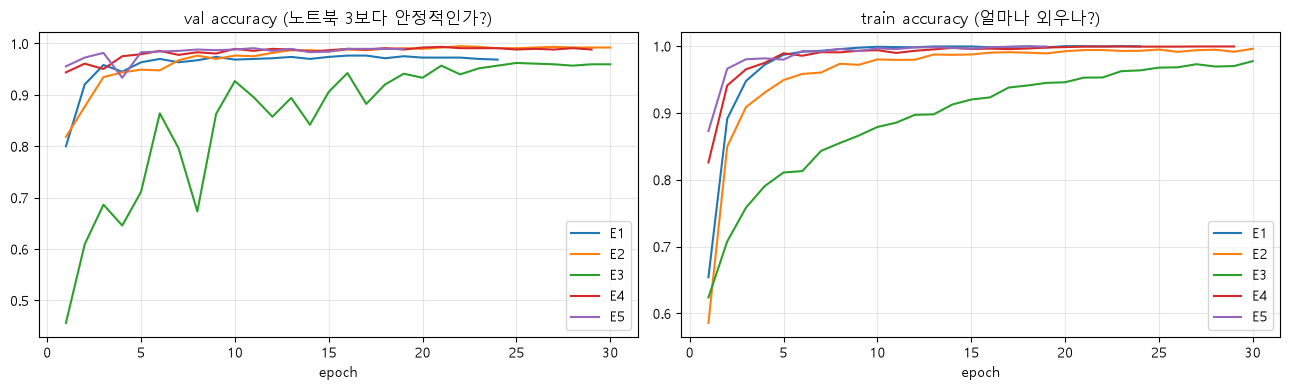

In [8]:
results = [json.load(open(f, encoding="utf-8")) for f in sorted(RES_DIR.glob("E*.json"))]
rows = [{"실험": "MLP (노트북 2)", "test_acc": 0.870, "test_macro_f1": 0.870},
        {"실험": "CNN lr3e-4+cosine (노트북 3)", "test_acc": 0.951, "test_macro_f1": 0.955}]
for r in results:
    rows.append({"실험": f"{r['tag']} {r['model'].split('.')[0]}"
                        f"{' 사전학습' if r['pretrained'] else ' 처음부터'}{' +자르기' if r['crop'] else ''}{' +증강' if r['aug'] else ''}",
                 **{k: r[k] for k in ["test_acc", "test_macro_f1", "test_auroc", "recall_glioma", "recall_meningioma",
                                      "recall_notumor", "recall_pituitary", "glioma→meningioma", "meningioma→glioma",
                                      "epochs_run", "minutes"]}})
comp = pd.DataFrame(rows).set_index("실험")
display(comp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for r in results:
    h = pd.DataFrame(r["history"])
    axes[0].plot(h["epoch"], h["val_acc"], label=r["tag"]); axes[1].plot(h["epoch"], h["train_acc"], label=r["tag"])
axes[0].set_title("val accuracy (노트북 3보다 안정적인가?)"); axes[1].set_title("train accuracy (얼마나 외우나?)")
for ax in axes: ax.legend(); ax.grid(alpha=.3); ax.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 7. 누수 실험 (가장 좋은 모델)

> 🎯 **왜 또?** 노트북 2에서 *"외울수록 누수가 점수를 부풀린다"*(MLP 60ep: +1.3%p), 노트북 3에서 *"CNN best 모델은 오히려 반대"*였어요.  
> 사전학습 모델은 train을 거의 100% 외우는 경우가 많아서, **강한 모델에서는 어떤지** 확인해요.  
> test macro F1이 가장 높은 실험으로 자동 선택해요.

In [9]:
best_r = max(results, key=lambda r: r["test_macro_f1"])
TAG = best_r["tag"]; cfg = EXPERIMENTS[TAG]
print(f"선택된 모델: {TAG} ({cfg['model']}) | 마지막 train acc {best_r['history'][-1]['train_acc']:.3f}")

model = create_model(cfg["model"], False).to(DEVICE)
model.load_state_dict(torch.load(OUT / f"p1_04_{TAG}.pt", map_location=DEVICE))
key = "crop" if cfg["crop"] else "raw"

orig_test = full[full["split"] == "test"].reset_index(drop=True)
leak_only = orig_test[orig_test["test_leak"]].reset_index(drop=True)
rows = []
for name, d in [("① 깨끗한 test", test_df), ("② 원본 test", orig_test), ("③ 누수 이미지만", leak_only)]:
    c = cache["test"] if d is test_df else build_cache(d, name)
    res = evaluate(model, DataLoader(CachedDS(c[key], c["y"], eval_tf), batch_size=128))
    by_cls = pd.Series(res["probs"].argmax(1) == res["y"]).groupby(d["label"].values).mean()
    rows.append({"평가셋": name, "장수": len(d), "acc": res["acc"], **by_cls.to_dict()})
pd.DataFrame(rows).set_index("평가셋").round(3)

선택된 모델: E4 (efficientnet_b0.ra_in1k) | 마지막 train acc 0.999


③ 누수 이미지만: 100%|██████████| 413/413 [00:03<00:00, 106.43it/s]


,장수,acc,glioma,meningioma,notumor,pituitary
평가셋,,,,,,
① 깨끗한 test,882,0.995,0.997,0.995,1.0,0.993
② 원본 test,1311,0.997,0.997,0.997,1.0,0.993
③ 누수 이미지만,413,1.000,1.000,1.000,1.0,1.000


## 8. Grad-CAM 비교: 자르기+증강이 "보는 곳"을 바꿨나? ⭐

> 🎯 **이 노트북의 핵심 질문 2번.** 같은 ResNet50인데 **E1(원본 그대로) vs E2(자르기+증강)**의 Grad-CAM을 같은 사진에서 비교해요.  
> 노트북 3에서 notumor·pituitary가 **머리 테두리**를 봤는데, E2에서는 **뇌 안쪽**으로 옮겨가는지 보세요.  
> (E1·E2를 둘 다 돌렸을 때만 실행돼요. ViT는 구조가 달라서 Grad-CAM을 이 방식으로 적용하지 않아요.)

C:\Users\louis\AppData\Local\Temp\ipykernel_41276\947919831.py:30: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  plt.suptitle("각 사진: 원본 | E1 (원본 그대로) Grad-CAM | E2 (자르기+증강) Grad-CAM"); plt.tight_layout(); plt.show()
d:\yerimlee\medimg-study\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


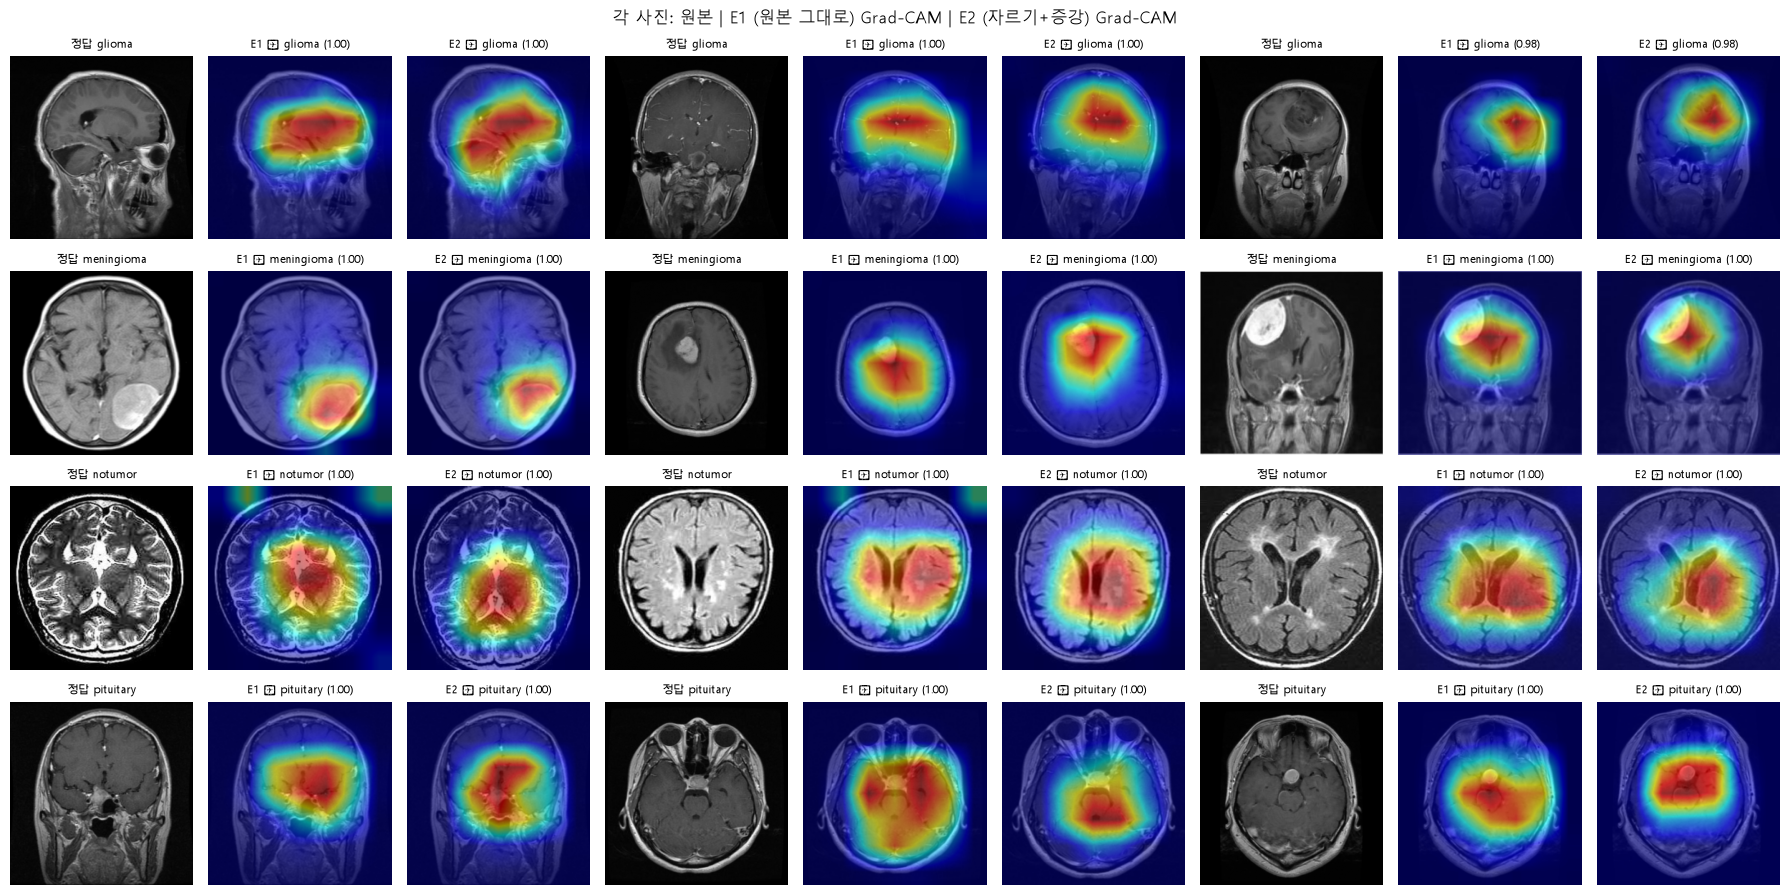

In [10]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

def load_trained(tag):
    m = create_model(EXPERIMENTS[tag]["model"], False).to(DEVICE)
    m.load_state_dict(torch.load(OUT / f"p1_04_{tag}.pt", map_location=DEVICE)); return m.eval()

if all((OUT / f"p1_04_{t}.pt").exists() for t in ["E1", "E2"]):
    models = {t: load_trained(t) for t in ["E1", "E2"]}
    cams = {t: GradCAM(model=m, target_layers=[m.layer4[-1]]) for t, m in models.items()}
    rng = np.random.default_rng(0); N = 3
    fig, axes = plt.subplots(len(CLASSES), N * 3, figsize=(N * 6, len(CLASSES) * 2.3))
    for row, cls in enumerate(CLASSES):
        idxs = rng.choice(np.where(test_df["label"] == cls)[0], N, replace=False)
        for k, i in enumerate(idxs):
            axes[row, k * 3].imshow(cache["test"]["raw"][i, 0], cmap="gray"); axes[row, k * 3].set_title(f"정답 {cls}", fontsize=8)
            for j, t in enumerate(["E1", "E2"]):
                key = "crop" if EXPERIMENTS[t]["crop"] else "raw"
                x, _ = CachedDS(cache["test"][key], cache["test"]["y"], eval_tf)[i]
                x = x.unsqueeze(0).to(DEVICE)
                with torch.no_grad():
                    p = torch.softmax(models[t](x).float(), 1)[0]
                heat = cams[t](input_tensor=x, targets=None)[0]
                img = eval_tf(cache["test"][key][i]).float().div(255)[0].numpy()
                ax = axes[row, k * 3 + 1 + j]
                ax.imshow(show_cam_on_image(np.stack([img] * 3, -1), heat, use_rgb=True))
                ok = p.argmax().item() == CLS2IDX[cls]
                ax.set_title(f"{t} {'✓' if ok else '✗'} {CLASSES[p.argmax()]} ({p.max():.2f})", fontsize=8, color="black" if ok else "red")
    for ax in axes.ravel(): ax.axis("off")
    plt.suptitle("각 사진: 원본 | E1 (원본 그대로) Grad-CAM | E2 (자르기+증강) Grad-CAM"); plt.tight_layout(); plt.show()
else:
    print("E1과 E2를 둘 다 돌려야 비교할 수 있어요.")

## 📝 메모: 노트북 4 결과 — 사전학습 모델 전이학습

### 1. 실험 설계 (한 번에 한 가지만 바꿔서 비교)
| 실험 | 모델 | 사전학습 | 자르기 | 증강 | lr |
|---|---|---|---|---|---|
| E1 | ResNet50 | ✅ | ❌ | ❌ | 1e-4 |
| E2 | ResNet50 | ✅ | ✅ | ✅ | 1e-4 |
| E3 | ResNet50 | ❌ (처음부터) | ✅ | ✅ | 3e-4 |
| E4 | EfficientNet-B0 | ✅ | ✅ | ✅ | 3e-4 |
| E5 | ViT-Small | ✅ (ImageNet-21k) | ✅ | ✅ | 5e-5 |
- 공통: 3채널 224×224, ImageNet 정규화, AdamW(wd 1e-4) + cosine, 30 epoch / 조기 종료 patience 8, val macro F1 기준 best, 혼합 정밀도(AMP)
- 자르기 = 밝기 기준으로 머리 영역(가장 큰 덩어리)을 찾아 정사각형으로 자름 (규칙 기반, segmentation 아님)
- 증강(train만) = RandomResizedCrop(85~100%), 좌우 반전, ±10° 회전, 밝기·대비 ±20%

### 2. 결과 (clean test 882장)
| 모델 | test acc | macro F1 | AUROC | glioma | menin. | notumor | pituit. | g→m | m→g | epoch | 시간 |
|---|---|---|---|---|---|---|---|---|---|---|---|
| MLP (노트북 2) | 0.870 | 0.870 | | | | | | 46 | 30 | | |
| CNN (노트북 3, lr3e-4+cosine) | 0.951 | 0.955 | | | | | | | | | |
| E1 ResNet50 사전학습 | 0.977 | 0.979 | 0.998 | 0.963 | 0.974 | 1.000 | 0.986 | 10 | 3 | 24 | 8.5분 |
| E2 + 자르기 + 증강 | 0.988 | 0.988 | 1.000 | 0.976 | 1.000 | 1.000 | 0.986 | 7 | 0 | 30 | 18.0분 |
| E3 처음부터 | 0.972 | 0.973 | 0.998 | 0.956 | 0.949 | 1.000 | 0.993 | 12 | 3 | 30 | 18.0분 |
| **E4 EfficientNet-B0** | **0.995** | **0.996** | 1.000 | 0.997 | 0.995 | 1.000 | 0.993 | 1 | 0 | 29 | 20.2분 |
| E5 ViT-Small | 0.988 | 0.988 | 0.999 | 0.976 | 1.000 | 1.000 | 0.986 | 7 | 0 | 19 | 11.7분 |

### 3. 질문별 해석
**Q1. 사전학습 효과 (E2 vs E3)**
- test는 0.988 vs 0.972 (+1.6%p). E3도 노트북 3 CNN(0.951)보단 높음 → "나쁜 모델"이 아니라 "사전학습보다 조금 낮은 모델"
- **진짜 차이는 학습 과정**: 사전학습 모델들은 1~2 epoch만에 val 0.95 근처에서 시작해 거의 일직선. E3만 val 0.45에서 시작해 **노트북 3처럼 톱니 모양으로 크게 흔들리고** train도 천천히 오름
- → 사전학습의 효과는 최종 성능보다 **"빠르고 안정적인 학습"**에서 큼. 노트북 3의 val 불안정 문제가 사전학습으로 거의 해결됨

**Q2. 자르기 + 증강 효과 (E1 vs E2)**
- 0.977 → 0.988 (+1.1%p), meningioma→glioma 오분류 3 → 0
- E1은 24 epoch 조기 종료, E2는 30 epoch까지 계속 개선 → 증강이 외우기를 늦춰서 더 오래 배움 (train acc 곡선도 E2가 더 천천히 1.0에 접근)

**Q3. 구조 비교**
- **E4 EfficientNet-B0이 1등 (0.995, 882장 중 4장 오답)**: ResNet50의 약 1/6 크기(4.0M vs 23.5M)
- ViT(E5) = ResNet50(E2) = 0.988 → 사전학습이 충분하면 Transformer도 동등
- ⚠️ E2와 E4 차이는 6장 → 우연일 수 있음 → 노트북 5에서 bootstrap 신뢰구간으로 확인

**Q4. 누수 (E4 기준)**
| 평가셋 | 장수 | acc | glioma | menin. | notumor | pituit. |
|---|---|---|---|---|---|---|
| ① 깨끗한 test | 882 | 0.995 | 0.997 | 0.995 | 1.0 | 0.993 |
| ② 원본 test | 1311 | 0.997 | 0.997 | 0.997 | 1.0 | 0.993 |
| ③ 누수 이미지만 | 413 | **1.000** | 1.000 | 1.000 | 1.0 | 1.000 |
- train을 거의 100% 외운 모델 → **누수 이미지는 하나도 안 틀림** (노트북 2 "외울수록 누수가 부풀린다"와 같은 방향)
- 차이가 0.2%p로 작은 건 이미 99.5%라 오를 여지(천장)가 거의 없어서. 성능이 낮은 데이터였다면 차이가 훨씬 컸을 것
- 노트북 2(MLP 60ep +1.3%p) → 노트북 3(CNN best는 오히려 반대) → 노트북 4(누수 이미지 100%): **누수 효과는 모델이 얼마나 외웠느냐에 따라 달라짐**

### 4. Grad-CAM 비교 (E1 vs E2, 클래스당 3장)
| 클래스 | 노트북 3 SimpleCNN | 노트북 4 ResNet50 |
|---|---|---|
| meningioma | 병변 + 테두리 | **종양 덩어리 쪽에 집중** |
| pituitary | 종양이 보여도 테두리·눈 쪽 (0.99 확신) | **axial 사진에서 가운데 동그란 종양을 정확히 감쌈** ✓ |
| notumor | 머리 양옆 테두리 | 뇌 안쪽 가운데(뇌실 주변)로 이동 |
| glioma | 테두리에 기댐 | 뇌 안쪽 넓은 영역 |
- **머리 테두리를 보던 문제가 거의 사라짐**
- **E1과 E2가 거의 같음** → 테두리를 안 보게 된 건 자르기+증강이 아니라 **사전학습 모델이라서**로 보임 (1,400만 장으로 "물체 모양 보는 법"을 이미 배운 상태에서 출발)
- 주의:
  - notumor가 **뇌실** 쪽을 봄 → "정상 구조 확인"인지 "T2라서 뇌실이 하얀 스타일"을 보는 건지 Grad-CAM만으론 구분 불가
  - notumor는 **MLP부터 모든 모델에서 거의 1.000** → 쉬운 단서가 여전히 있을 가능성
  - ResNet50 Grad-CAM은 7×7 기반이라 노트북 3(16×16)보다 더 뭉툭 → glioma처럼 넓게 퍼진 영역은 병변을 본 건지 애매

### 5. 결론과 한계
- 사전학습 모델로 **test 99%대** 달성. 이 데이터의 천장에 가까움
- 하지만 이 데이터는 원래 **쉬운 편으로 알려진 공개 데이터** → 성능을 더 올리기보다 **"이 99%를 믿을 수 있는가"**를 검증하는 게 더 가치 있음
- 남은 질문 → 노트북 5
  1. 모델 간 차이(E4 vs E2, 6장)는 진짜인가? → bootstrap 신뢰구간, McNemar
  2. 남은 오답은 모델 실수인가 라벨 오류인가?
  3. notumor 1.000은 지름길인가? → 저해상도 테스트, 테두리만/안쪽만 실험, Grad-CAM 정량화
  4. 확률(99% 확신)을 믿을 수 있나? → 보정(calibration)
- 근본 한계: 단면 한 장으로 4분류하는 건 실제 진료(수십 장 단면 판독)를 많이 단순화한 문제 / 외부 병원 데이터 검증 없음

## ✍️ 정리 & 생각해볼 질문

1. **사전학습 효과** (E2 vs E3): 같은 ResNet50인데 성능과 학습 속도가 얼마나 달랐나?
2. **자르기+증강 효과** (E1 vs E2): 성능은? Grad-CAM은 테두리에서 뇌 안쪽으로 옮겨갔나? 특히 notumor·pituitary.
3. **구조 비교** (E2 vs E4 vs E5): 파라미터 수 대비 성능은? 어느 모델을 고르겠나?
4. **val 안정성**: 노트북 3 CNN처럼 val이 크게 튀었나? 증강·사전학습이 도움이 됐나?
5. **누수**: 강한 모델에서 ② − ① 차이는? 노트북 2·3과 비교하면?
6. 노트북 3 CNN(0.4M 파라미터)과 ResNet50(23.5M)의 성능 차이가 크지 않다면, 그건 무슨 의미일까?

**메모:**
- 
